# Topic 22c - Bivariate exploration

The main lesson looked at one categorical pair (station type) and one numeric pair (wind speed). This notebook practices more pairs - including two that turn out not to relate, which is just as important a result as one that does.

Work through it after reading section 4 of the [main lesson](topic22_exploratory_data_analysis.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "exploratory_data_analysis" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "air_quality_readings.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find air_quality_readings.csv. Looked in: " +
        ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette (Topic 21) - fixed hue order, never cycled, so a category
# keeps the same colour in every chart it appears in.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"
STATION_TYPE_COLOR = {
    "Roadside": PALETTE["red"], "Industrial": PALETTE["orange"],
    "Residential": PALETTE["aqua"], "Background": PALETTE["blue"],
}
STATION_TYPE_ORDER = ["Roadside", "Industrial", "Residential", "Background"]

WHO_ANNUAL_GUIDELINE = 5.0   # ug/m3, PM2.5 annual mean
WHO_24H_GUIDELINE = 15.0     # ug/m3, PM2.5 24-hour mean

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/exploratory_data_analysis/data
files:             ['air_quality_readings.csv', 'air_quality_readings_assignment.csv', 'air_quality_stations.csv', 'air_quality_stations_assignment.csv', 'customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
stations = pd.read_csv(DATA_DIR / "air_quality_stations.csv")
readings = pd.read_csv(DATA_DIR / "air_quality_readings.csv", parse_dates=["date"])

aq = readings.merge(stations, on="station_id", how="left", validate="m:1")
aq["month"] = aq["date"].dt.month
aq["is_weekend"] = aq["date"].dt.dayofweek.isin([5, 6])
aq["is_harmattan"] = aq["month"].isin([12, 1, 2])

print(f"Air-quality table: {aq.shape[0]} rows x {aq.shape[1]} columns")
print(f"Stations: {aq['station_id'].nunique()}, dates: {aq['date'].min().date()} to {aq['date'].max().date()}")
print(f"Missing pm2_5 readings: {aq['pm2_5'].isna().sum()}")

Air-quality table: 3285 rows x 14 columns
Stations: 9, dates: 2023-01-01 to 2023-12-31
Missing pm2_5 readings: 7


---

## Two numeric variables that barely relate

Not every plausible pair is actually related. `no2` and `wind_speed_kmh` are worth checking - wind disperses particulates, so might it disperse NO2 too?

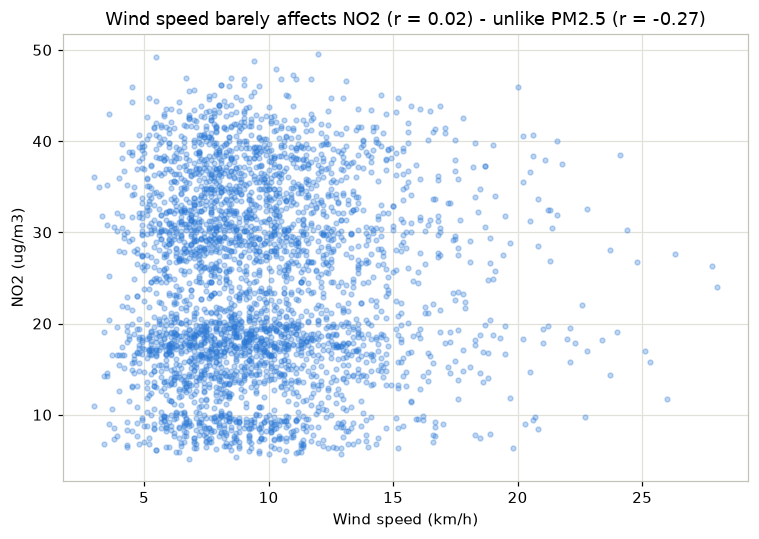

In [3]:
r = aq["wind_speed_kmh"].corr(aq["no2"])
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(aq["wind_speed_kmh"], aq["no2"], s=10, alpha=0.3, color=PALETTE["blue"])
ax.set_title(f"Wind speed barely affects NO2 (r = {r:.2f}) - unlike PM2.5 (r = -0.27)")
ax.set_xlabel("Wind speed (km/h)")
ax.set_ylabel("NO2 (ug/m3)")
fig.tight_layout()
plt.show()

That near-zero correlation is a real finding, not a failed chart. NO2 comes mostly from combustion (traffic, generators) right at the point of measurement; it does not travel and disperse the way airborne dust does, so wind has much less effect on it than it does on PM2.5. The *difference* between the two r-values (-0.27 vs -0.01) is more informative than either one alone.

---

## A categorical pair: does the weekday effect hold everywhere?

The main lesson found weekday NO2 higher than weekend NO2 overall. Is that one citywide pattern, or does it only show up at certain station types?

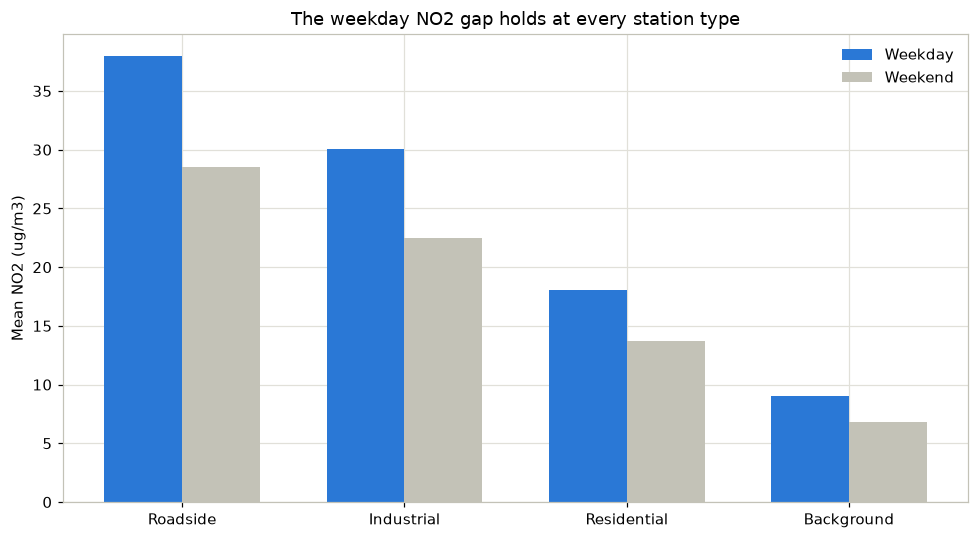

              Weekday  Weekend  gap_pct
station_type                           
Roadside         37.9     28.6     32.8
Industrial       30.0     22.5     33.5
Residential      18.0     13.7     31.8
Background        9.1      6.8     32.5


In [4]:
by_type = aq.groupby(["station_type", "is_weekend"])["no2"].mean().unstack()
by_type.columns = ["Weekday", "Weekend"]
by_type = by_type.loc[STATION_TYPE_ORDER]
by_type["gap_pct"] = ((by_type["Weekday"] / by_type["Weekend"] - 1) * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(STATION_TYPE_ORDER))
width = 0.35
ax.bar(x - width/2, by_type["Weekday"], width, label="Weekday", color=PALETTE["blue"])
ax.bar(x + width/2, by_type["Weekend"], width, label="Weekend", color=MUTED)
ax.set_xticks(x)
ax.set_xticklabels(STATION_TYPE_ORDER)
ax.set_title("The weekday NO2 gap holds at every station type")
ax.set_ylabel("Mean NO2 (ug/m3)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(by_type.round(1).to_string())

It holds everywhere, with a similar roughly 30% gap at each type. That is a stronger claim than the citywide average alone: "the weekday effect is consistent across every kind of location," not just true on average.

### Try It 5 - a confounded pair

Plot `pm2_5` against `humidity_pct`. You will find a negative correlation. Before concluding "humidity reduces particulate matter," check: does humidity also correlate with `month` or with the Harmattan season? Write one sentence about what is really driving the relationship you see.

In [5]:
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic22_exploratory_data_analysis.ipynb)
- Previous: [22b - Univariate exploration](topic22b_univariate_exploration.ipynb)
- Next: [22d - Multivariate exploration](topic22d_multivariate_exploration.ipynb)